<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 first stage Landing Prediction**


# Lab 1: Collecting the data


Estimated time needed: **45** minutes


In this capstone, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because SpaceX can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against SpaceX for a rocket launch. In this lab, you will collect and make sure the data is in the correct format from an API. The following is an example of a successful and launch.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/lab_v2/images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/lab_v2/images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans. 


## Objectives


In this lab, you will make a get request to the SpaceX API. You will also do some basic data wrangling and formating. 

- Request to the SpaceX API
- Clean the requested data


----


## Import Libraries and Define Auxiliary Functions


We will import the following libraries into the lab


In [1]:
# Requests allows us to make HTTP requests which we will use to get data from an API
import requests
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
# NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Datetime is a library that allows us to represent dates
import datetime

# Setting this option will print all collumns of a dataframe
pd.set_option('display.max_columns', None)
# Setting this option will print all of the data in a feature
pd.set_option('display.max_colwidth', None)

Below we will define a series of helper functions that will help us use the API to extract information using identification numbers in the launch data.

From the <code>rocket</code> column we would like to learn the booster name.


In [2]:
# Takes the dataset and uses the rocket column to call the API and append the data to the list
def getBoosterVersion(data):
    for x in data['rocket']:
       if x:
        response = requests.get("https://api.spacexdata.com/v4/rockets/"+str(x)).json()
        BoosterVersion.append(response['name'])

From the <code>launchpad</code> we would like to know the name of the launch site being used, the logitude, and the latitude.


In [3]:
# Takes the dataset and uses the launchpad column to call the API and append the data to the list
def getLaunchSite(data):
    for x in data['launchpad']:
       if x:
         response = requests.get("https://api.spacexdata.com/v4/launchpads/"+str(x)).json()
         Longitude.append(response['longitude'])
         Latitude.append(response['latitude'])
         LaunchSite.append(response['name'])

From the <code>payload</code> we would like to learn the mass of the payload and the orbit that it is going to.


In [4]:
# Takes the dataset and uses the payloads column to call the API and append the data to the lists
def getPayloadData(data):
    for load in data['payloads']:
       if load:
        response = requests.get("https://api.spacexdata.com/v4/payloads/"+load).json()
        PayloadMass.append(response['mass_kg'])
        Orbit.append(response['orbit'])

From <code>cores</code> we would like to learn the outcome of the landing, the type of the landing, number of flights with that core, whether gridfins were used, wheter the core is reused, wheter legs were used, the landing pad used, the block of the core which is a number used to seperate version of cores, the number of times this specific core has been reused, and the serial of the core.


In [5]:
# Takes the dataset and uses the cores column to call the API and append the data to the lists
def getCoreData(data):
    for core in data['cores']:
            if core['core'] != None:
                response = requests.get("https://api.spacexdata.com/v4/cores/"+core['core']).json()
                Block.append(response['block'])
                ReusedCount.append(response['reuse_count'])
                Serial.append(response['serial'])
            else:
                Block.append(None)
                ReusedCount.append(None)
                Serial.append(None)
            Outcome.append(str(core['landing_success'])+' '+str(core['landing_type']))
            Flights.append(core['flight'])
            GridFins.append(core['gridfins'])
            Reused.append(core['reused'])
            Legs.append(core['legs'])
            LandingPad.append(core['landpad'])

Now let's start requesting rocket launch data from SpaceX API with the following URL:


In [6]:
spacex_url="https://api.spacexdata.com/v4/launches/past"

In [7]:
response = requests.get(spacex_url)

Check the content of the response


In [8]:
print(response.content)

b'<!DOCTYPE html>\n<!--[if lt IE 7]> <html class="no-js ie6 oldie" lang="en-US"> <![endif]-->\n<!--[if IE 7]>    <html class="no-js ie7 oldie" lang="en-US"> <![endif]-->\n<!--[if IE 8]>    <html class="no-js ie8 oldie" lang="en-US"> <![endif]-->\n<!--[if gt IE 8]><!--> <html class="no-js" lang="en-US"> <!--<![endif]-->\n<head>\n\n<title>spacexdata.com | 522: Connection timed out</title>\n<meta charset="UTF-8" />\n<meta http-equiv="Content-Type" content="text/html; charset=UTF-8" />\n<meta http-equiv="X-UA-Compatible" content="IE=Edge" />\n<meta name="robots" content="noindex, nofollow" />\n<meta name="viewport" content="width=device-width,initial-scale=1" />\n<link rel="stylesheet" id="cf_styles-css" href="/cdn-cgi/styles/main.css" />\n</head>\n<body>\n<div id="cf-wrapper">\n    <div id="cf-error-details" class="p-0">\n        <header class="mx-auto pt-10 lg:pt-6 lg:px-8 w-240 lg:w-full mb-8">\n            <h1 class="inline-block sm:block sm:mb-2 font-light text-60 lg:text-4xl text-bla

You should see the response contains massive information about SpaceX launches. Next, let's try to discover some more relevant information for this project.


### Task 1: Request and parse the SpaceX launch data using the GET request


To make the requested JSON results more consistent, we will use the following static response object for this project:


In [9]:
static_json_url='https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/API_call_spacex_api.json'

We should see that the request was successfull with the 200 status response code


In [10]:
response=requests.get(static_json_url)

In [11]:
response.status_code

200

Now we decode the response content as a Json using <code>.json()</code> and turn it into a Pandas dataframe using <code>.json_normalize()</code>


In [12]:
# Use json_normalize meethod to convert the json result into a dataframe
json_result = response.json()

Using the dataframe <code>data</code> print the first 5 rows


In [13]:
# Get the head of the dataframe
data = pd.json_normalize(json_result)
# Display the first 5 rows
data.head()

,static_fire_date_utc,static_fire_date_unix,tbd,net,window,rocket,success,details,crew,ships,capsules,payloads,launchpad,auto_update,failures,flight_number,name,date_utc,date_unix,date_local,date_precision,upcoming,cores,id,fairings.reused,fairings.recovery_attempt,fairings.recovered,fairings.ships,links.patch.small,links.patch.large,links.reddit.campaign,links.reddit.launch,links.reddit.media,links.reddit.recovery,links.flickr.small,links.flickr.original,links.presskit,links.webcast,links.youtube_id,links.article,links.wikipedia,fairings
0,2006-03-17T00:00:00.000Z,1.142554e+09,False,False,0.0,5e9d0d95eda69955f709d1eb,False,Engine failure at 33 seconds and loss of vehicle,[],[],[],[5eb0e4b5b6c3bb0006eeb1e1],5e9e4502f5090995de566f86,True,"[{'time': 33, 'altitude': None, 'reason': 'merlin engine failure'}]",1,FalconSat,2006-03-24T22:30:00.000Z,1143239400,2006-03-25T10:30:00+12:00,hour,False,"[{'core': '5e9e289df35918033d3b2623', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}]",5eb87cd9ffd86e000604b32a,False,False,False,[],https://images2.imgbox.com/3c/0e/T8iJcSN3_o.png,https://images2.imgbox.com/40/e3/GypSkayF_o.png,None,None,None,None,[],[],None,https://www.youtube.com/watch?v=0a_00nJ_Y88,0a_00nJ_Y88,https://www.space.com/2196-spacex-inaugural-falcon-1-rocket-lost-launch.html,https://en.wikipedia.org/wiki/DemoSat,NaN
1,None,NaN,False,False,0.0,5e9d0d95eda69955f709d1eb,False,"Successful first stage burn and transition to second stage, maximum altitude 289 km, Premature engine shutdown at T+7 min 30 s, Failed to reach orbit, Failed to recover first stage",[],[],[],[5eb0e4b6b6c3bb0006eeb1e2],5e9e4502f5090995de566f86,True,"[{'time': 301, 'altitude': 289, 'reason': 'harmonic oscillation leading to premature engine shutdown'}]",2,DemoSat,2007-03-21T01:10:00.000Z,1174439400,2007-03-21T13:10:00+12:00,hour,False,"[{'core': '5e9e289ef35918416a3b2624', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}]",5eb87cdaffd86e000604b32b,False,False,False,[],https://images2.imgbox.com/4f/e3/I0lkuJ2e_o.png,https://images2.imgbox.com/be/e7/iNqsqVYM_o.png,None,None,None,None,[],[],None,https://www.youtube.com/watch?v=Lk4zQ2wP-Nc,Lk4zQ2wP-Nc,https://www.space.com/3590-spacex-falcon-1-rocket-fails-reach-orbit.html,https://en.wikipedia.org/wiki/DemoSat,NaN
2,None,NaN,False,False,0.0,5e9d0d95eda69955f709d1eb,False,Residual stage 1 thrust led to collision between stage 1 and stage 2,[],[],[],"[5eb0e4b6b6c3bb0006eeb1e3, 5eb0e4b6b6c3bb0006eeb1e4]",5e9e4502f5090995de566f86,True,"[{'time': 140, 'altitude': 35, 'reason': 'residual stage-1 thrust led to collision between stage 1 and stage 2'}]",3,Trailblazer,2008-08-03T03:34:00.000Z,1217734440,2008-08-03T15:34:00+12:00,hour,False,"[{'core': '5e9e289ef3591814873b2625', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}]",5eb87cdbffd86e000604b32c,False,False,False,[],https://images2.imgbox.com/3d/86/cnu0pan8_o.png,https://images2.imgbox.com/4b/bd/d8UxLh4q_o.png,None,None,None,None,[],[],None,https://www.youtube.com/watch?v=v0w9p3U8860,v0w9p3U8860,http://www.spacex.com/news/2013/02/11/falcon-1-flight-3-mission-summary,https://en.wikipedia.org/wiki/Trailblazer_(satellite),NaN
3,2008-09-20T00:00:00.000Z,1.221869e+09,False,False,0.0,5e9d0d95eda69955f709d1eb,True,"Ratsat was carried to orbit on the first successful orbital launch of any privately funded and developed, liquid-propelled carrier rocket, the SpaceX Falcon 1",[],[],[],[5eb0e4b7b6c3bb0006eeb1e5],5e9e4502f5090995de566f86,True,[],4,RatSat,2008-09-28T23:15:00.000Z,1222643700,2008-09-28T11:15:00+12:00,hour,False,"[{'core': '5e9e289ef3591855dc3b2626', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_succes

You will notice that a lot of the data are IDs. For example the rocket column has no information about the rocket just an identification number.

We will now use the API again to get information about the launches using the IDs given for each launch. Specifically we will be using columns <code>rocket</code>, <code>payloads</code>, <code>launchpad</code>, and <code>cores</code>.


In [14]:
# Lets take a subset of our dataframe keeping only the features we want and the flight number, and date_utc.
data = data[['rocket', 'payloads', 'launchpad', 'cores', 'flight_number', 'date_utc']]

# We will remove rows with multiple cores because those are falcon rockets with 2 extra rocket boosters and rows that have multiple payloads in a single rocket.
data = data[data['cores'].map(len)==1]
data = data[data['payloads'].map(len)==1]

# Since payloads and cores are lists of size 1 we will also extract the single value in the list and replace the feature.
data['cores'] = data['cores'].map(lambda x : x[0])
data['payloads'] = data['payloads'].map(lambda x : x[0])

# We also want to convert the date_utc to a datetime datatype and then extracting the date leaving the time
data['date'] = pd.to_datetime(data['date_utc']).dt.date

# Using the date we will restrict the dates of the launches
data = data[data['date'] <= datetime.date(2020, 11, 13)]

* From the <code>rocket</code> we would like to learn the booster name

* From the <code>payload</code> we would like to learn the mass of the payload and the orbit that it is going to

* From the <code>launchpad</code> we would like to know the name of the launch site being used, the longitude, and the latitude.

* **From <code>cores</code> we would like to learn the outcome of the landing, the type of the landing, number of flights with that core, whether gridfins were used, whether the core is reused, whether legs were used, the landing pad used, the block of the core which is a number used to seperate version of cores, the number of times this specific core has been reused, and the serial of the core.**

The data from these requests will be stored in lists and will be used to create a new dataframe.


In [15]:
data.head()

,rocket,payloads,launchpad,cores,flight_number,date_utc,date
0,5e9d0d95eda69955f709d1eb,5eb0e4b5b6c3bb0006eeb1e1,5e9e4502f5090995de566f86,"{'core': '5e9e289df35918033d3b2623', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",1,2006-03-24T22:30:00.000Z,2006-03-24
1,5e9d0d95eda69955f709d1eb,5eb0e4b6b6c3bb0006eeb1e2,5e9e4502f5090995de566f86,"{'core': '5e9e289ef35918416a3b2624', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",2,2007-03-21T01:10:00.000Z,2007-03-21
3,5e9d0d95eda69955f709d1eb,5eb0e4b7b6c3bb0006eeb1e5,5e9e4502f5090995de566f86,"{'core': '5e9e289ef3591855dc3b2626', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",4,2008-09-28T23:15:00.000Z,2008-09-28
4,5e9d0d95eda69955f709d1eb,5eb0e4b7b6c3bb0006eeb1e6,5e9e4502f5090995de566f86,"{'core': '5e9e289ef359184f103b2627', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",5,2009-07-13T03:35:00.000Z,2009-07-13
5,5e9d0d95eda69973a809d1ec,5eb0e4b7b6c3bb0006eeb1e7,5e9e4501f509094ba4566f84,"{'core': '5e9e289ef359185f2b3b2628', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",6,2010-06-04T18:45:00.000Z,2010-06-04


In [16]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 94 entries, 0 to 105
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   rocket         94 non-null     object
 1   payloads       94 non-null     object
 2   launchpad      94 non-null     object
 3   cores          94 non-null     object
 4   flight_number  94 non-null     int64 
 5   date_utc       94 non-null     object
 6   date           94 non-null     object
dtypes: int64(1), object(6)
memory usage: 5.9+ KB


In [17]:
data['date'] = pd.to_datetime(data['date_utc'])

In [18]:
data[['date_utc','date']].head()

,date_utc,date
0,2006-03-24T22:30:00.000Z,2006-03-24 22:30:00+00:00
1,2007-03-21T01:10:00.000Z,2007-03-21 01:10:00+00:00
3,2008-09-28T23:15:00.000Z,2008-09-28 23:15:00+00:00
4,2009-07-13T03:35:00.000Z,2009-07-13 03:35:00+00:00
5,2010-06-04T18:45:00.000Z,2010-06-04 18:45:00+00:00


In [19]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 94 entries, 0 to 105
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   rocket         94 non-null     object             
 1   payloads       94 non-null     object             
 2   launchpad      94 non-null     object             
 3   cores          94 non-null     object             
 4   flight_number  94 non-null     int64              
 5   date_utc       94 non-null     object             
 6   date           94 non-null     datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](1), int64(1), object(5)
memory usage: 5.9+ KB


In [20]:
#Global variables 
BoosterVersion = []
PayloadMass = []
Orbit = []
LaunchSite = []
Outcome = []
Flights = []
GridFins = []
Reused = []
Legs = []
LandingPad = []
Block = []
ReusedCount = []
Serial = []
Longitude = []
Latitude = []

These functions will apply the outputs globally to the above variables. Let's take a looks at <code>BoosterVersion</code> variable. Before we apply  <code>getBoosterVersion</code> the list is empty:


In [21]:
BoosterVersion

[]

Now, let's apply <code> getBoosterVersion</code> function method to get the booster version


In [22]:
rocket_id = '5e9d0d95eda69955f709d1eb'

if rocket_id == '5e9d0d95eda69955f709d1eb':
    print("Booster Version: Falcon 1")

Booster Version: Falcon 1


In [23]:
rocket_id_2 = '5e9d0d95eda69973a809d1ec'

if rocket_id_2 == '5e9d0d95eda69973a809d1ec':
    print("Booster Version: Falcon 9")

Booster Version: Falcon 9


In [25]:
def getBoosterVersion(data):
    for rocket_id in data['rocket']:
        if rocket_id == '5e9d0d95eda69955f709d1eb':
            BoosterVersion.append('Falcon 1')
        elif rocket_id == '5e9d0d95eda69973a809d1ec':
            BoosterVersion.append('Falcon 9')
        else:
            BoosterVersion.append('Unknown')

the list has now been update 


In [26]:
BoosterVersion[0:5]

[]

we can apply the rest of the  functions here:


In [27]:
def getLaunchSite(data):
    for x in data['launchpad']:
        if x:
            response = requests.get(
                "https://api.spacexdata.com/v4/launchpads/" + str(x)
            ).json()
            Longitude.append(response['longitude'])
            Latitude.append(response['latitude'])
            LaunchSite.append(response['name'])

In [28]:
print("Plataformas de lanzamiento encontradas:")
print(data['launchpad'].value_counts())

Plataformas de lanzamiento encontradas:
5e9e4501f509094ba4566f84    55
5e9e4502f509094188566f88    22
5e9e4502f509092b78566f87    13
5e9e4502f5090995de566f86     4
Name: launchpad, dtype: int64


In [29]:
def getLaunchSite(data):

    launchpads = {
        '5e9e4501f509094ba4566f84': {
            'name': 'CCAFS SLC-40',
            'longitude': -80.577366,
            'latitude': 28.5618571
        },
        '5e9e4502f509094188566f88': {
            'name': 'KSC LC-39A',
            'longitude': -80.6039558,
            'latitude': 28.6080585
        },
        '5e9e4502f509092b78566f87': {
            'name': 'VAFB SLC-4E',
            'longitude': -120.610829,
            'latitude': 34.632093
        },
        '5e9e4502f5090995de566f86': {
            'name': 'Kwajalein Atoll',
            'longitude': 167.7431292,
            'latitude': 9.0477206
        }
    }

    for x in data['launchpad']:
        if x in launchpads:
            response = launchpads[x]

            Longitude.append(response['longitude'])
            Latitude.append(response['latitude'])
            LaunchSite.append(response['name'])

In [30]:
LaunchSite.clear()
Longitude.clear()
Latitude.clear()

getLaunchSite(data)

In [31]:
print("Total de LaunchSite:", len(LaunchSite))
print("Total de Longitude:", len(Longitude))
print("Total de Latitude:", len(Latitude))

print(pd.Series(LaunchSite).value_counts())

Total de LaunchSite: 94
Total de Longitude: 94
Total de Latitude: 94
CCAFS SLC-40       55
KSC LC-39A         22
VAFB SLC-4E        13
Kwajalein Atoll     4
dtype: int64


### Revisar los identificadores de los payloads

In [32]:
print("Primeros 5 registros de payloads:")
print(data['payloads'].head())

print("\nTipo de dato:")
print(type(data['payloads'].iloc[0]))

Primeros 5 registros de payloads:
0    5eb0e4b5b6c3bb0006eeb1e1
1    5eb0e4b6b6c3bb0006eeb1e2
3    5eb0e4b7b6c3bb0006eeb1e5
4    5eb0e4b7b6c3bb0006eeb1e6
5    5eb0e4b7b6c3bb0006eeb1e7
Name: payloads, dtype: object

Tipo de dato:
<class 'str'>


### Prueba si la API original permite consultar el primer payload

In [33]:
payload_id = data['payloads'].iloc[0][0]

url = f"https://api.spacexdata.com/v4/payloads/{payload_id}"

response = requests.get(url, timeout=30)

print("Payload ID:", payload_id)
print("Status:", response.status_code)
print(response.text[:500])

Payload ID: 5
Status: 522
<!DOCTYPE html>
<!--[if lt IE 7]> <html class="no-js ie6 oldie" lang="en-US"> <![endif]-->
<!--[if IE 7]>    <html class="no-js ie7 oldie" lang="en-US"> <![endif]-->
<!--[if IE 8]>    <html class="no-js ie8 oldie" lang="en-US"> <![endif]-->
<!--[if gt IE 8]><!--> <html class="no-js" lang="en-US"> <!--<![endif]-->
<head>

<title>spacexdata.com | 522: Connection timed out</title>
<meta charset="UTF-8" />
<meta http-equiv="Content-Type" content="text/html; charset=UTF-8" />
<meta http-equiv="X-UA-C


In [34]:
payload_id = data['payloads'].iloc[0]

print("Payload ID completo:", payload_id)
print("Tipo de dato:", type(payload_id))

Payload ID completo: 5eb0e4b5b6c3bb0006eeb1e1
Tipo de dato: <class 'str'>


In [35]:
print("Cantidad de lanzamientos:", len(data))

print("Cantidad de payloads únicos:",
      data['payloads'].nunique())

print("\nPrimeros 10 payloads:")
print(data['payloads'].head(10))

Cantidad de lanzamientos: 94
Cantidad de payloads únicos: 94

Primeros 10 payloads:
0     5eb0e4b5b6c3bb0006eeb1e1
1     5eb0e4b6b6c3bb0006eeb1e2
3     5eb0e4b7b6c3bb0006eeb1e5
4     5eb0e4b7b6c3bb0006eeb1e6
5     5eb0e4b7b6c3bb0006eeb1e7
7     5eb0e4bab6c3bb0006eeb1ea
9     5eb0e4bbb6c3bb0006eeb1ed
10    5eb0e4bbb6c3bb0006eeb1ee
11    5eb0e4bbb6c3bb0006eeb1ef
12    5eb0e4bbb6c3bb0006eeb1f0
Name: payloads, dtype: object


In [36]:
url = "https://gateway.pipeworx.io/spacex/v4/launches/past"

response = requests.get(url, timeout=30)

print("Status:", response.status_code)
print(response.text[:500])

Status: 200
[
 {
  "name": "Falcon 9 Block 5 | Starlink Group 15-18",
  "status": "Launch Successful",
  "success": true,
  "date_utc": "2026-10-31T04:04:34Z"
 },
 {
  "name": "Falcon 9 Block 5 | Starlink Group 15-16",
  "status": "Launch Successful",
  "success": true,
  "date_utc": "2026-10-27T07:25:51Z"
 },
 {
  "name": "Falcon 9 Block 5 | Starlink Group 15-15",
  "status": "Launch Successful",
  "success": true,
  "date_utc": "2026-10-23T22:48:44Z"
 },
 {
  "name": "Falcon 9 Block 5 | Bandwagon 5 (Dedic


In [37]:
launches_json = response.json()

launches_df = pd.DataFrame(launches_json)

print("Columnas disponibles:")
print(launches_df.columns.tolist())

print("\nPrimeros registros:")
display(launches_df.head())

Columnas disponibles:
['name', 'status', 'success', 'date_utc']

Primeros registros:


,name,status,success,date_utc
0,Falcon 9 Block 5 | Starlink Group 15-18,Launch Successful,True,2026-10-31T04:04:34Z
1,Falcon 9 Block 5 | Starlink Group 15-16,Launch Successful,True,2026-10-27T07:25:51Z
2,Falcon 9 Block 5 | Starlink Group 15-15,Launch Successful,True,2026-10-23T22:48:44Z
3,Falcon 9 Block 5 | Bandwagon 5 (Dedicated Mid-Inclination Rideshare),Launch Successful,True,2026-10-20T11:04:00Z
4,Falcon 9 Block 5 | USSF-481,Launch Successful,True,2026-10-16T00:01:05Z


In [38]:
for columna in launches_df.columns:
    print(columna)

name
status
success
date_utc


In [39]:
payload_id = data['payloads'].iloc[0]

ask_url = "https://gateway.pipeworx.io/ask"

response = requests.get(
    ask_url,
    params={
        "q": f"Find the SpaceX payload with ID {payload_id}. Return its mass in kg and orbit."
    },
    timeout=30
)

print("Status:", response.status_code)

result = response.json()

print("\nPregunta:")
print(result.get('question'))

print("\nRespuesta:")
print(result.get('answer'))

Status: 200

Pregunta:
Find the SpaceX payload with ID 5eb0e4b5b6c3bb0006eeb1e1. Return its mass in kg and orbit.

Respuesta:
{'error': 'no_match', 'filter_gap': 'payload_id: 5eb0e4b5b6c3bb0006eeb1e1 — no available tool accepts SpaceX payload IDs or retrieves payload metadata (mass, orbit) by ID', 'filter_gap_note': 'No tool was run. The router named a qualifier it could not satisfy: payload_id: 5eb0e4b5b6c3bb0006eeb1e1 — no available tool accepts SpaceX payload IDs or retrieves payload metadata (mass, orbit) by ID. If the question can supply that in a form a tool accepts (a code, an identifier, a narrower subject), ask again with it.', 'message': 'Sorry — we could not match that question to a source. Either no tool in our live-data catalog covers it, or the closest candidates (under did_you_mean — call one directly if it fits) were judged not to answer it. That is a gap on our side rather than a statement about whether the information exists. It has been added to our demand log, which

In [40]:
def getPayloadData(data):
    for load in data['payloads']:
        response = requests.get(
            "https://api.spacexdata.com/v4/payloads/" + load
        ).json()
        PayloadMass.append(response['mass_kg'])
        Orbit.append(response['orbit'])

## Recuperar Datos Historicos


In [41]:
import pandas as pd

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_1.csv"

historical_data = pd.read_csv(url)

print("Dimensiones:", historical_data.shape)

print("\nColumnas:")
print(historical_data.columns.tolist())

display(historical_data.head())

Dimensiones: (90, 17)

Columnas:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [42]:
## Revisamos el conjunto historico
historical_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
dtypes: bool(3), float64(4), int64(3), obj

In [43]:
historical_data[['FlightNumber', 'BoosterVersion',
                 'PayloadMass', 'Orbit', 'LaunchSite']].head(10)

,FlightNumber,BoosterVersion,PayloadMass,Orbit,LaunchSite
0,1,Falcon 9,6104.959412,LEO,CCAFS SLC 40
1,2,Falcon 9,525.000000,LEO,CCAFS SLC 40
2,3,Falcon 9,677.000000,ISS,CCAFS SLC 40
3,4,Falcon 9,500.000000,PO,VAFB SLC 4E
4,5,Falcon 9,3170.000000,GTO,CCAFS SLC 40
5,6,Falcon 9,3325.000000,GTO,CCAFS SLC 40
6,7,Falcon 9,2296.000000,ISS,CCAFS SLC 40
7,8,Falcon 9,1316.000000,LEO,CCAFS SLC 40
8,9,Falcon 9,4535.000000,GTO,CCAFS SLC 40
9,10,Falcon 9,4428.000000,GTO,CCAFS SLC 40


In [44]:
historical_data.isnull().sum()

FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
dtype: int64

In [45]:
BoosterVersion = historical_data['BoosterVersion'].tolist()
PayloadMass = historical_data['PayloadMass'].tolist()
Orbit = historical_data['Orbit'].tolist()
LaunchSite = historical_data['LaunchSite'].tolist()
Outcome = historical_data['Outcome'].tolist()
Flights = historical_data['Flights'].tolist()
GridFins = historical_data['GridFins'].tolist()
Reused = historical_data['Reused'].tolist()
Legs = historical_data['Legs'].tolist()
LandingPad = historical_data['LandingPad'].tolist()
Block = historical_data['Block'].tolist()
ReusedCount = historical_data['ReusedCount'].tolist()
Serial = historical_data['Serial'].tolist()
Longitude = historical_data['Longitude'].tolist()
Latitude = historical_data['Latitude'].tolist()

In [46]:
print("BoosterVersion:", len(BoosterVersion))
print("PayloadMass:", len(PayloadMass))
print("Orbit:", len(Orbit))
print("LaunchSite:", len(LaunchSite))

BoosterVersion: 90
PayloadMass: 90
Orbit: 90
LaunchSite: 90


In [47]:
# Verificar las dimensiones del conjunto histórico
print("Número de lanzamientos:", historical_data.shape[0])
print("Número de columnas:", historical_data.shape[1])

# Mostrar las columnas disponibles
print("\nColumnas del dataset:")
print(historical_data.columns.tolist())

# Revisar los primeros registros
display(historical_data.head())

Número de lanzamientos: 90
Número de columnas: 17

Columnas del dataset:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [48]:
# Crear una copia del conjunto de datos histórico
df = historical_data.copy()

# Revisar las dimensiones
print("Dimensiones del DataFrame:", df.shape)

# Revisar los primeros 5 registros
display(df.head())

# Revisar los tipos de datos
df.info()

Dimensiones del DataFrame: (90, 17)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
dtypes: bool(3), float64(4), int64(3), obj

In [49]:
# Revisar valores nulos por columna
print("Valores nulos por columna:")
print(df.isnull().sum())

# Calcular porcentaje de valores nulos
print("\nPorcentaje de valores nulos:")
print((df.isnull().sum() / len(df) * 100).round(2))

# Revisar registros duplicados
print("\nNúmero de registros duplicados:")
print(df.duplicated().sum())

Valores nulos por columna:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
dtype: int64

Porcentaje de valores nulos:
FlightNumber       0.00
Date               0.00
BoosterVersion     0.00
PayloadMass        0.00
Orbit              0.00
LaunchSite         0.00
Outcome            0.00
Flights            0.00
GridFins           0.00
Reused             0.00
Legs               0.00
LandingPad        28.89
Block              0.00
ReusedCount        0.00
Serial             0.00
Longitude          0.00
Latitude           0.00
dtype: float64

Número de registros duplicados:
0


In [50]:
# Convertir Date a formato datetime
df['Date'] = pd.to_datetime(df['Date'])

# Comprobar el tipo de dato
print(df['Date'].dtype)

# Mostrar las primeras fechas
display(df[['FlightNumber', 'Date']].head())

datetime64[ns]


,FlightNumber,Date
0,1,2010-06-04
1,2,2012-05-22
2,3,2013-03-01
3,4,2013-09-29
4,5,2013-12-03


In [51]:
# Revisar los valores únicos de las variables categóricas

print("Versiones de cohetes:")
print(df['BoosterVersion'].unique())

print("\nÓrbitas:")
print(df['Orbit'].unique())

print("\nSitios de lanzamiento:")
print(df['LaunchSite'].unique())

print("\nResultados de aterrizaje:")
print(df['Outcome'].unique())

Versiones de cohetes:
['Falcon 9']

Órbitas:
['LEO' 'ISS' 'PO' 'GTO' 'ES-L1' 'SSO' 'HEO' 'MEO' 'VLEO' 'SO' 'GEO']

Sitios de lanzamiento:
['CCAFS SLC 40' 'VAFB SLC 4E' 'KSC LC 39A']

Resultados de aterrizaje:
['None None' 'False Ocean' 'True Ocean' 'False ASDS' 'None ASDS'
 'True RTLS' 'True ASDS' 'False RTLS']


In [52]:
# Estadísticas descriptivas de las variables numéricas
display(df.describe())

,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Longitude,Latitude
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,45.500000,6104.959412,1.788889,3.500000,1.655556,-86.366477,29.449963
std,26.124701,4694.671720,1.213172,1.595288,1.710254,14.149518,2.141306
min,1.000000,350.000000,1.000000,1.000000,0.000000,-120.610829,28.561857
25%,23.250000,2510.750000,1.000000,2.000000,0.000000,-80.603956,28.561857
50%,45.500000,4701.500000,1.000000,4.000000,1.000000,-80.577366,28.561857
75%,67.750000,8912.750000,2.000000,5.000000,3.000000,-80.577366,28.608058
max,90.000000,15600.000000,6.000000,5.000000,5.000000,-80.577366,34.632093


In [53]:
# Estadísticas descriptivas de las variables numéricas
display(df.describe())

,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Longitude,Latitude
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,45.500000,6104.959412,1.788889,3.500000,1.655556,-86.366477,29.449963
std,26.124701,4694.671720,1.213172,1.595288,1.710254,14.149518,2.141306
min,1.000000,350.000000,1.000000,1.000000,0.000000,-120.610829,28.561857
25%,23.250000,2510.750000,1.000000,2.000000,0.000000,-80.603956,28.561857
50%,45.500000,4701.500000,1.000000,4.000000,1.000000,-80.577366,28.561857
75%,67.750000,8912.750000,2.000000,5.000000,3.000000,-80.577366,28.608058
max,90.000000,15600.000000,6.000000,5.000000,5.000000,-80.577366,34.632093


In [54]:
# Contar lanzamientos por sitio
launch_counts = df['LaunchSite'].value_counts()

print(launch_counts)

# Calcular porcentajes
launch_percentages = df['LaunchSite'].value_counts(normalize=True) * 100

print("\nPorcentaje de lanzamientos por sitio:")
print(launch_percentages.round(2))

CCAFS SLC 40    55
KSC LC 39A      22
VAFB SLC 4E     13
Name: LaunchSite, dtype: int64

Porcentaje de lanzamientos por sitio:
CCAFS SLC 40    61.11
KSC LC 39A      24.44
VAFB SLC 4E     14.44
Name: LaunchSite, dtype: float64


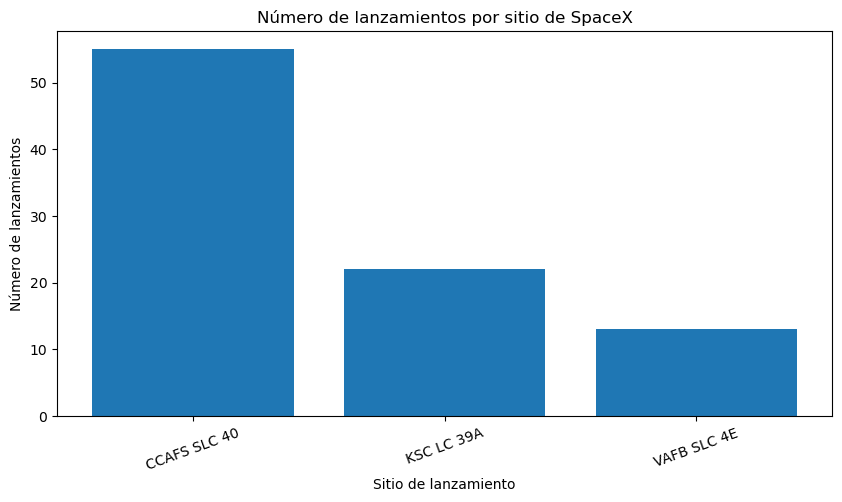

In [55]:
import matplotlib.pyplot as plt

# Crear el tamaño del gráfico
plt.figure(figsize=(10, 5))

# Crear gráfico de barras
plt.bar(launch_counts.index, launch_counts.values)

# Agregar título y nombres de los ejes
plt.title('Número de lanzamientos por sitio de SpaceX')
plt.xlabel('Sitio de lanzamiento')
plt.ylabel('Número de lanzamientos')

# Rotar las etiquetas del eje X
plt.xticks(rotation=20)

# Mostrar el gráfico
plt.show()

### Conclusión:

CCAFS SLC 40 concentra la mayor cantidad de lanzamientos, con aproximadamente el 61 % del total.

In [56]:
# Contar lanzamientos por tipo de órbita
orbit_counts = df['Orbit'].value_counts()

print("Lanzamientos por órbita:")
print(orbit_counts)

# Calcular porcentajes
orbit_percentages = df['Orbit'].value_counts(normalize=True) * 100

print("\nPorcentaje por órbita:")
print(orbit_percentages.round(2))

Lanzamientos por órbita:
GTO      27
ISS      21
VLEO     14
PO        9
LEO       7
SSO       5
MEO       3
ES-L1     1
HEO       1
SO        1
GEO       1
Name: Orbit, dtype: int64

Porcentaje por órbita:
GTO      30.00
ISS      23.33
VLEO     15.56
PO       10.00
LEO       7.78
SSO       5.56
MEO       3.33
ES-L1     1.11
HEO       1.11
SO        1.11
GEO       1.11
Name: Orbit, dtype: float64


In [57]:
# Contar lanzamientos por tipo de órbita
orbit_counts = df['Orbit'].value_counts()

print("Lanzamientos por órbita:")
print(orbit_counts)

# Calcular porcentajes
orbit_percentages = df['Orbit'].value_counts(normalize=True) * 100

print("\nPorcentaje por órbita:")
print(orbit_percentages.round(2))

Lanzamientos por órbita:
GTO      27
ISS      21
VLEO     14
PO        9
LEO       7
SSO       5
MEO       3
ES-L1     1
HEO       1
SO        1
GEO       1
Name: Orbit, dtype: int64

Porcentaje por órbita:
GTO      30.00
ISS      23.33
VLEO     15.56
PO       10.00
LEO       7.78
SSO       5.56
MEO       3.33
ES-L1     1.11
HEO       1.11
SO        1.11
GEO       1.11
Name: Orbit, dtype: float64


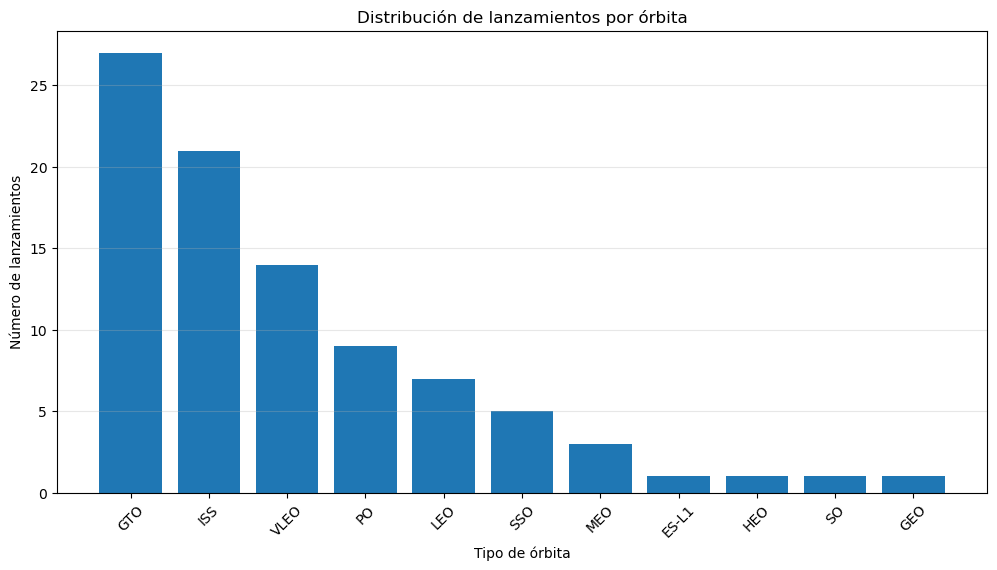

In [58]:
import matplotlib.pyplot as plt

orbit_counts = df['Orbit'].value_counts()

plt.figure(figsize=(12, 6))

plt.bar(orbit_counts.index, orbit_counts.values)

plt.title('Distribución de lanzamientos por órbita')
plt.xlabel('Tipo de órbita')
plt.ylabel('Número de lanzamientos')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.show()

### Conclusiones:
- GTO es la órbita con mayor cantidad de lanzamientos (30 %).
- ISS ocupa el segundo lugar (23,33 %).
- GTO e ISS representan conjuntamente el 53,33 % de los lanzamientos.
- Las órbitas ES-L1, HEO, SO y GEO tienen un lanzamiento cada una.

In [59]:
## Analizar resultados  de aterrizaje 
# Contar los resultados de aterrizaje
outcome_counts = df['Outcome'].value_counts()

print("Resultados de aterrizaje:")
print(outcome_counts)

Resultados de aterrizaje:
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: Outcome, dtype: int64


In [60]:
# Extraer el año de cada lanzamiento
df['Year'] = df['Date'].dt.year

# Contar los lanzamientos por año
launches_per_year = df['Year'].value_counts().sort_index()

print("Lanzamientos por año:")
print(launches_per_year) 

Lanzamientos por año:
2010     1
2012     1
2013     3
2014     6
2015     6
2016     8
2017    18
2018    18
2019    10
2020    19
Name: Year, dtype: int64


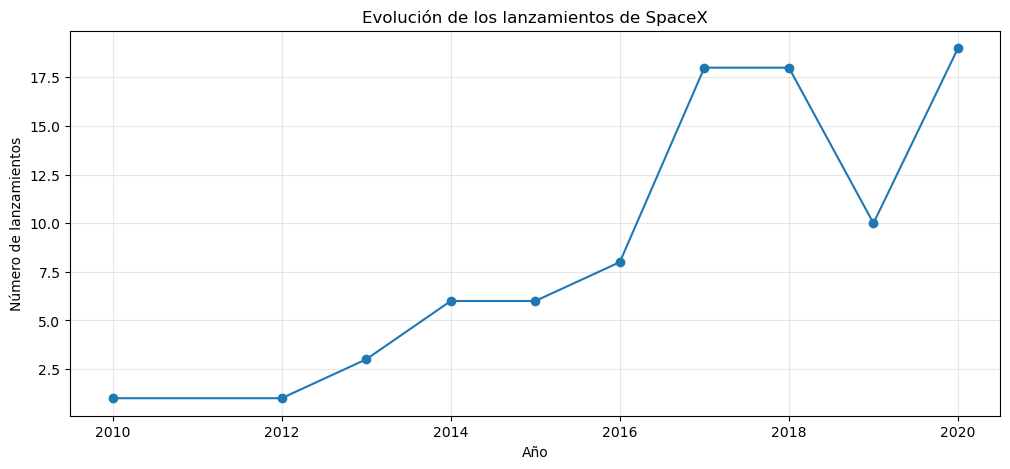

In [61]:
plt.figure(figsize=(12, 5))

plt.plot(
    launches_per_year.index,
    launches_per_year.values,
    marker='o'
)

plt.title('Evolución de los lanzamientos de SpaceX')
plt.xlabel('Año')
plt.ylabel('Número de lanzamientos')

plt.grid(True, alpha=0.3)
plt.show()

### Conclusiones

1. En 2010 se registró un solo lanzamiento.
2. Entre 2014 y 2016 hubo un crecimiento progresivo.
3. En 2017 y 2018 se alcanzaron 18 lanzamientos por año.
4. En 2019 hubo una disminución a 10 lanzamientos.
5. En 2020 se alcanzó el máximo del conjunto analizado: 19 lanzamientos.

#### Interpretación:
Los registros muestran un crecimiento importante de la actividad de lanzamiento de SpaceX, especialmente desde 2017. Sin embargo, estamos analizando únicamente el periodo 2010–2020 de este dataset.

In [62]:
# Estadísticas de la masa de carga útil
print("Masa promedio:", df['PayloadMass'].mean(), "kg")
print("Masa mínima:", df['PayloadMass'].min(), "kg")
print("Masa máxima:", df['PayloadMass'].max(), "kg")
print("Mediana:", df['PayloadMass'].median(), "kg")

Masa promedio: 6104.959411764707 kg
Masa mínima: 350.0 kg
Masa máxima: 15600.0 kg
Mediana: 4701.5 kg


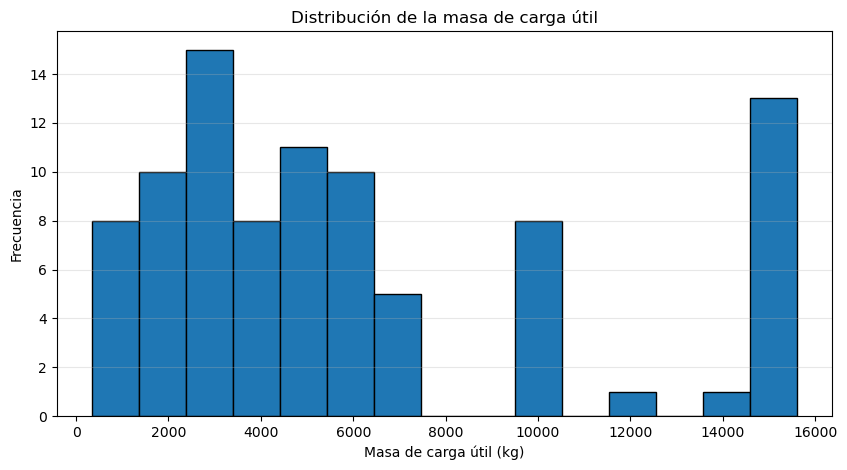

In [63]:
plt.figure(figsize=(10, 5))

plt.hist(df['PayloadMass'], bins=15, edgecolor='black')

plt.title('Distribución de la masa de carga útil')
plt.xlabel('Masa de carga útil (kg)')
plt.ylabel('Frecuencia')

plt.grid(axis='y', alpha=0.3)
plt.show()

### Task 2: Filter the dataframe to only include `Falcon 9` launches


Finally we will remove the Falcon 1 launches keeping only the Falcon 9 launches. Filter the data dataframe using the <code>BoosterVersion</code> column to only keep the Falcon 9 launches. Save the filtered data to a new dataframe called <code>data_falcon9</code>.


In [64]:
# Identificar el ID correspondiente al Falcon 9
falcon9_id = '5e9d0d95eda69973a809d1ec'

# Filtrar únicamente los lanzamientos Falcon 9
data_falcon9 = data[data['rocket'] == falcon9_id].copy()

# Comprobar el resultado
print("Dimensiones del conjunto Falcon 9:", data_falcon9.shape)

# Mostrar los primeros registros
display(data_falcon9.head())


Dimensiones del conjunto Falcon 9: (90, 7)


,rocket,payloads,launchpad,cores,flight_number,date_utc,date
5,5e9d0d95eda69973a809d1ec,5eb0e4b7b6c3bb0006eeb1e7,5e9e4501f509094ba4566f84,"{'core': '5e9e289ef359185f2b3b2628', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",6,2010-06-04T18:45:00.000Z,2010-06-04 18:45:00+00:00
7,5e9d0d95eda69973a809d1ec,5eb0e4bab6c3bb0006eeb1ea,5e9e4501f509094ba4566f84,"{'core': '5e9e289ef35918f39c3b262a', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",8,2012-05-22T07:44:00.000Z,2012-05-22 07:44:00+00:00
9,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ed,5e9e4501f509094ba4566f84,"{'core': '5e9e289ff3591884e03b262c', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",10,2013-03-01T19:10:00.000Z,2013-03-01 19:10:00+00:00
10,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ee,5e9e4502f509092b78566f87,"{'core': '5e9e289ff359180ae23b262d', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': True, 'landing_success': False, 'landing_type': 'Ocean', 'landpad': None}",11,2013-09-29T16:00:00.000Z,2013-09-29 16:00:00+00:00
11,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ef,5e9e4501f509094ba4566f84,"{'core': '5e9e289ff35918862c3b262e', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",12,2013-12-03T22:41:00.000Z,2013-12-03 22:41:00+00:00


### Preparamos los datos para el analisis


In [65]:
# Revisar las columnas del conjunto Falcon 9
print("Columnas disponibles:")
print(data_falcon9.columns.tolist())

# Revisar información general
data_falcon9.info()

# Mostrar los primeros registros
display(data_falcon9.head())

Columnas disponibles:
['rocket', 'payloads', 'launchpad', 'cores', 'flight_number', 'date_utc', 'date']
<class 'pandas.core.frame.DataFrame'>
Int64Index: 90 entries, 5 to 105
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   rocket         90 non-null     object             
 1   payloads       90 non-null     object             
 2   launchpad      90 non-null     object             
 3   cores          90 non-null     object             
 4   flight_number  90 non-null     int64              
 5   date_utc       90 non-null     object             
 6   date           90 non-null     datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](1), int64(1), object(5)
memory usage: 5.6+ KB


,rocket,payloads,launchpad,cores,flight_number,date_utc,date
5,5e9d0d95eda69973a809d1ec,5eb0e4b7b6c3bb0006eeb1e7,5e9e4501f509094ba4566f84,"{'core': '5e9e289ef359185f2b3b2628', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",6,2010-06-04T18:45:00.000Z,2010-06-04 18:45:00+00:00
7,5e9d0d95eda69973a809d1ec,5eb0e4bab6c3bb0006eeb1ea,5e9e4501f509094ba4566f84,"{'core': '5e9e289ef35918f39c3b262a', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",8,2012-05-22T07:44:00.000Z,2012-05-22 07:44:00+00:00
9,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ed,5e9e4501f509094ba4566f84,"{'core': '5e9e289ff3591884e03b262c', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",10,2013-03-01T19:10:00.000Z,2013-03-01 19:10:00+00:00
10,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ee,5e9e4502f509092b78566f87,"{'core': '5e9e289ff359180ae23b262d', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': True, 'landing_success': False, 'landing_type': 'Ocean', 'landpad': None}",11,2013-09-29T16:00:00.000Z,2013-09-29 16:00:00+00:00
11,5e9d0d95eda69973a809d1ec,5eb0e4bbb6c3bb0006eeb1ef,5e9e4501f509094ba4566f84,"{'core': '5e9e289ff35918862c3b262e', 'flight': 1, 'gridfins': False, 'legs': False, 'reused': False, 'landing_attempt': False, 'landing_success': None, 'landing_type': None, 'landpad': None}",12,2013-12-03T22:41:00.000Z,2013-12-03 22:41:00+00:00


In [66]:
## Ordenar los lanzamientos por fecha

data_falcon9 = data_falcon9.sort_values(
    by='date'
).reset_index(drop=True)

# Mostrar los primeros y últimos lanzamientos
print("Primeros lanzamientos:")
display(data_falcon9[['flight_number', 'date']].head())

print("\nÚltimos lanzamientos:")
display(data_falcon9[['flight_number', 'date']].tail())

Primeros lanzamientos:


,flight_number,date
0,6,2010-06-04 18:45:00+00:00
1,8,2012-05-22 07:44:00+00:00
2,10,2013-03-01 19:10:00+00:00
3,11,2013-09-29 16:00:00+00:00
4,12,2013-12-03 22:41:00+00:00



Últimos lanzamientos:


,flight_number,date
85,102,2020-09-03 12:46:00+00:00
86,103,2020-10-06 11:29:00+00:00
87,104,2020-10-18 12:25:00+00:00
88,105,2020-10-24 15:31:00+00:00
89,106,2020-11-05 23:24:00+00:00


## Revisar la distribución temporal

In [67]:
# Extraer el año de cada lanzamiento
data_falcon9['year'] = data_falcon9['date'].dt.year

# Contar lanzamientos por año
launches_by_year = data_falcon9['year'].value_counts().sort_index()

print("Lanzamientos Falcon 9 por año:")
print(launches_by_year)

Lanzamientos Falcon 9 por año:
2010     1
2012     1
2013     3
2014     6
2015     6
2016     8
2017    18
2018    18
2019    10
2020    19
Name: year, dtype: int64


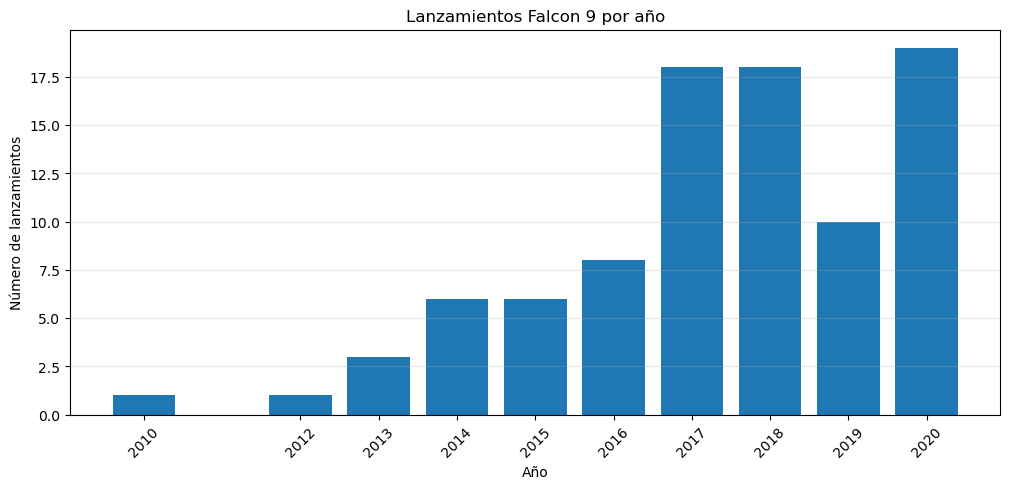

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(launches_by_year.index, launches_by_year.values)

plt.title('Lanzamientos Falcon 9 por año')
plt.xlabel('Año')
plt.ylabel('Número de lanzamientos')

plt.xticks(launches_by_year.index, rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.show()

## Verificar los números de vuelo

In [69]:
# Revisar cantidad de números de vuelo únicos
print("Números de vuelo únicos:",
      data_falcon9['flight_number'].nunique())

# Revisar valores duplicados
print("Números de vuelo duplicados:",
      data_falcon9['flight_number'].duplicated().sum())

# Revisar mínimo y máximo
print("Primer número de vuelo:",
      data_falcon9['flight_number'].min())

print("Último número de vuelo:",
      data_falcon9['flight_number'].max())

Números de vuelo únicos: 90
Números de vuelo duplicados: 0
Primer número de vuelo: 6
Último número de vuelo: 106


### Conclusión: 
Tenemos 90 registros de lanzamientos Falcon 9, sin números de vuelo repetidos. El hecho de que los números vayan del 6 al 106 no significa que falten registros dentro de nuestro DataFrame; los números corresponden a la numeración histórica de vuelos, no al índice de panda

## Revisar los datos de las columnas principales

In [70]:
print("Cantidad de lanzamientos:", len(data_falcon9))

print("\nCantidad de cohetes:")
print(data_falcon9['rocket'].value_counts())

print("\nCantidad de plataformas de lanzamiento:")
print(data_falcon9['launchpad'].value_counts())

print("\nCantidad de cargas útiles:")
print(data_falcon9['payloads'].nunique())

print("\nCantidad de fechas:")
print(data_falcon9['date'].nunique())

Cantidad de lanzamientos: 90

Cantidad de cohetes:
5e9d0d95eda69973a809d1ec    90
Name: rocket, dtype: int64

Cantidad de plataformas de lanzamiento:
5e9e4501f509094ba4566f84    55
5e9e4502f509094188566f88    22
5e9e4502f509092b78566f87    13
Name: launchpad, dtype: int64

Cantidad de cargas útiles:
90

Cantidad de fechas:
90


#### Preparar el resumen de lanzamiento por plataforma

In [71]:
launches_by_site = (
    data_falcon9['launchpad']
    .value_counts()
    .reset_index()
)

launches_by_site.columns = ['launchpad_id', 'total_launches']

launches_by_site['percentage'] = (
    launches_by_site['total_launches'] / len(data_falcon9) * 100
).round(2)

display(launches_by_site)

,launchpad_id,total_launches,percentage
0,5e9e4501f509094ba4566f84,55,61.11
1,5e9e4502f509094188566f88,22,24.44
2,5e9e4502f509092b78566f87,13,14.44


In [72]:
print("Valores faltantes por columna:")
print(data_falcon9.isnull().sum())

Valores faltantes por columna:
rocket           0
payloads         0
launchpad        0
cores            0
flight_number    0
date_utc         0
date             0
year             0
dtype: int64


## Data Wrangling


We can see below that some of the rows are missing values in our dataset.


In [ ]:
data_falcon9.isnull().sum()

Before we can continue we must deal with these missing values. The <code>LandingPad</code> column will retain None values to represent when landing pads were not used.


### Task 3: Dealing with Missing Values


Calculate below the mean for the <code>PayloadMass</code> using the <code>.mean()</code>. Then use the mean and the <code>.replace()</code> function to replace `np.nan` values in the data with the mean you calculated.


In [73]:
print("Columnas de data_falcon9:")
print(data_falcon9.columns.tolist())

print("\nColumnas de df:")
print(df.columns.tolist())

Columnas de data_falcon9:
['rocket', 'payloads', 'launchpad', 'cores', 'flight_number', 'date_utc', 'date', 'year']

Columnas de df:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Year']


## Comprobar valores faltantes

In [74]:
print("Valores faltantes en PayloadMass:")
print(df['PayloadMass'].isnull().sum())

print("\nValores faltantes en todo el dataset:")
print(df.isnull().sum())

Valores faltantes en PayloadMass:
0

Valores faltantes en todo el dataset:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
Year               0
dtype: int64


In [75]:
import numpy as np

# Calcular la media de PayloadMass
payload_mass_mean = df['PayloadMass'].mean()

print("Media de PayloadMass:", payload_mass_mean)

# Reemplazar los valores NaN por la media
df['PayloadMass'] = df['PayloadMass'].replace(
    np.nan,
    payload_mass_mean
)

# Comprobar que ya no existan valores faltantes
print("Valores faltantes después del reemplazo:")
print(df['PayloadMass'].isnull().sum())

Media de PayloadMass: 6104.959411764707
Valores faltantes después del reemplazo:
0


In [76]:
# Crear una copia con las 17 columnas originales
dataset_part_1 = df.drop(columns=['Year'], errors='ignore').copy()

# Exportar a CSV
dataset_part_1.to_csv('dataset_part_1.csv', index=False)

print("Archivo exportado correctamente.")
print("Dimensiones del dataset:", dataset_part_1.shape)

Archivo exportado correctamente.
Dimensiones del dataset: (90, 17)


In [77]:
print(dataset_part_1.isnull().sum())

FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
dtype: int64


#### Conclusión final – Proyecto SpaceX: Recopilación y preparación de datos

A través de las tres tareas desarrolladas en este laboratorio, se logró recopilar, explorar y preparar información histórica de los lanzamientos de SpaceX, con especial atención a los cohetes Falcon 9.

En la primera tarea se trabajó en la recopilación de datos mediante la API de SpaceX y en la transformación de la información JSON en estructuras de datos utilizando Python y Pandas. Debido a inconvenientes de conexión con algunos endpoints de la API, también se utilizó un conjunto de datos histórico proporcionado por IBM como fuente complementaria para continuar el análisis.

En la segunda tarea se filtraron los registros correspondientes a Falcon 9, obteniendo un conjunto de 90 lanzamientos. Se verificó la integridad de los registros, comprobando que no existieran números de vuelo duplicados ni valores faltantes en el conjunto obtenido de la API. También se analizaron las plataformas de lanzamiento, identificando que una de ellas concentraba el 61,11 % de los lanzamientos.

Finalmente, en la tercera tarea se trabajó en el tratamiento de valores faltantes del conjunto histórico. Se calculó la media de la variable PayloadMass, obteniendo un valor aproximado de 6104,96 kg, y se aplicó el método de reemplazo con Pandas y NumPy. Posteriormente, se exportó el conjunto de datos preparado a un archivo CSV con 90 registros y 17 columnas, conservando los 26 valores faltantes de LandingPad, ya que representan información que no debe imputarse arbitrariamente.

En conclusión, este laboratorio permitió fortalecer habilidades fundamentales para el trabajo de un analista y científico de datos, como la obtención de información mediante APIs, la manipulación de datos con Pandas, la exploración de variables, la identificación de inconsistencias, el tratamiento de valores ausentes y la exportación de conjuntos de datos. Estas actividades constituyen una base esencial para las siguientes etapas del proyecto, en las que se analizarán los factores que pueden influir en el éxito del aterrizaje de la primera etapa de los cohetes Falcon 9.

You should see the number of missing values of the <code>PayLoadMass</code> change to zero.


Now we should have no missing values in our dataset except for in <code>LandingPad</code>.


We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range. 


<code>data_falcon9.to_csv('dataset_part_1.csv', index=False)</code>


## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


<!--## Change Log
-->


<!--

|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2020-09-20|1.1|Joseph|get result each time you run|
|2020-09-20|1.1|Azim |Created Part 1 Lab using SpaceX API|
|2020-09-20|1.0|Joseph |Modified Multiple Areas|
-->


Copyright ©IBM Corporation. All rights reserved.
